# Практика: Влияние инициализации и скорости обучения на MNIST

В этом практическом занятии мы исследуем, как начальная инициализация весов и скорость обучения влияют на обучение нейронной сети на реальном наборе данных MNIST (рукописные цифры). Мы будем использовать простую полносвязную сеть (MLP) с двумя скрытыми слоями.

**Цели:**
- Научиться загружать и подготавливать данные MNIST.
- Сравнить различные инициализации (по умолчанию, Xavier, He, случайная большая).
- Исследовать влияние скорости обучения на сходимость.
- Визуализировать процесс обучения и полученные признаки.

**Задание: повторить все действия и сделать выводы для набора данных Fashion-MNIST.**

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt

# Фиксируем seed для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

## 1. Загрузка и предобработка данных MNIST

Загрузим обучающую и тестовую выборки, нормализуем изображения и создадим DataLoader'ы. Для ускорения эксперимента возьмём только первые 10000 обучающих примеров и 2000 тестовых.

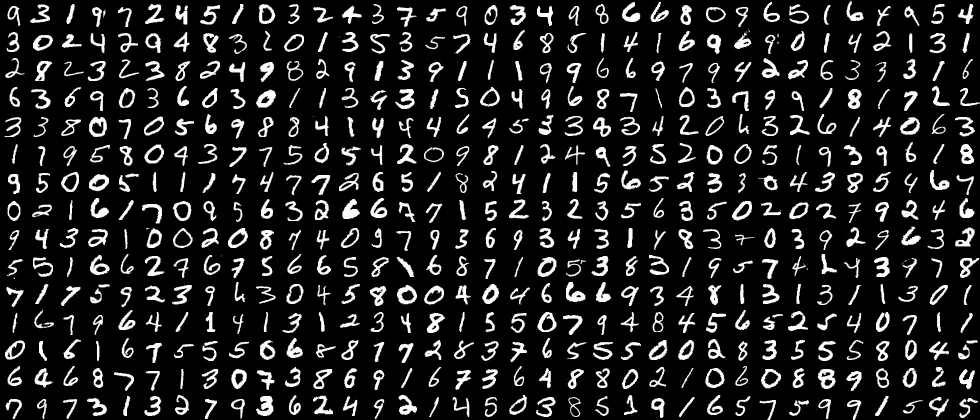

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # среднее и std для MNIST
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Ограничим выборку для быстроты
train_dataset = torch.utils.data.Subset(train_dataset, range(10000))
test_dataset = torch.utils.data.Subset(test_dataset, range(2000))

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

Failed to download (trying next):
HTTP Error 404: Not Found



  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:46, 211kB/s]

  1%|          | 65.5k/9.91M [00:00<00:47, 207kB/s]

  1%|▏         | 131k/9.91M [00:00<00:33, 292kB/s] 

...

Extracting ./data\MNIST\raw\t10k-images-idx3-ubyte.gz to ./data\MNIST\raw



Failed to download (trying next):
HTTP Error 404: Not Found



  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 4.54MB/s]

Extracting ./data\MNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\MNIST\raw



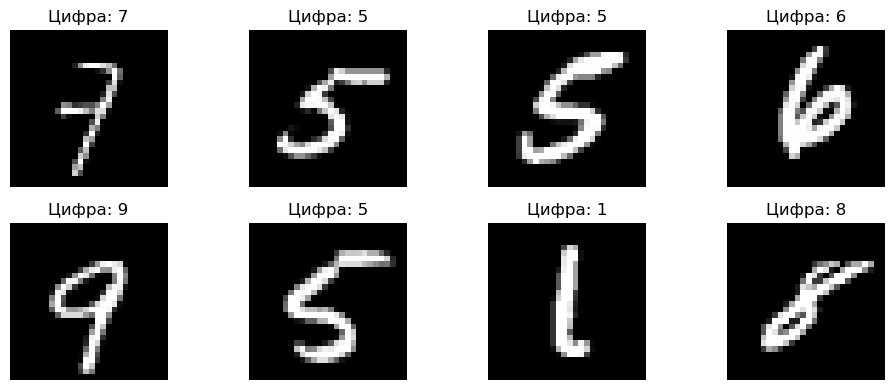

In [3]:
# Посмотрим на несколько изображений
images, labels = next(iter(train_loader))
plt.figure(figsize=(10,4))
for i in range(8):
    plt.subplot(2,4,i+1)
    plt.imshow(images[i][0], cmap='gray')
    plt.title(f'Цифра: {labels[i].item()}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Определение модели

Создадим MLP с двумя скрытыми слоями (256 и 128 нейронов) и выходным слоем на 10 классов (softmax не включаем, так как будем использовать CrossEntropyLoss).

In [4]:
class MLP(nn.Module):
    def __init__(self, input_size=784, hidden1=256, hidden2=128, output_size=10):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden2, output_size)
        # без softmax, его добавит loss

    def forward(self, x):
        x = x.view(x.size(0), -1)  # вытягиваем изображения в вектор
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

def init_weights(m, mode='default'):
    if isinstance(m, nn.Linear):
        if mode == 'normal':
            nn.init.normal_(m.weight, mean=0, std=1.0)
            nn.init.zeros_(m.bias)
        elif mode == 'xavier':
            nn.init.xavier_normal_(m.weight)
            nn.init.zeros_(m.bias)
        elif mode == 'he':
            nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            nn.init.zeros_(m.bias)
        elif mode == 'default':
            pass  # оставляем умолчательную

## 3. Функция для обучения и оценки

Определим функцию, которая принимает модель, загрузчики, число эпох, скорость обучения и тип инициализации, обучает и возвращает историю потерь и точности.

In [5]:
def train_and_evaluate(model, train_loader, test_loader, epochs=5, lr=0.01, init_mode='default'):
    model.apply(lambda m: init_weights(m, init_mode))
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)

    # Пустые массивы для накопления истории обучения
    train_losses = []
    test_losses = []
    train_accs = []
    test_accs = []

    for epoch in range(epochs):
        # Это только перевод в режим обучения
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        # Перебор всех жанных из обучающей выборки
        for images, labels in train_loader:
            optimizer.zero_grad()
            # Прямой проход
            outputs = model(images)
            # Текущее значение функции потерь
            loss = criterion(outputs, labels)
            # Обратное распространение ошибки.
            loss.backward()

            # обновление весов модели на основе градиентов.
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        # Обновление метрик после прохода всех данных
        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = correct_train / total_train
        train_losses.append(epoch_train_loss)
        train_accs.append(epoch_train_acc)

        # Оценка на тесте
        model.eval()
        test_loss = 0.0
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for images, labels in test_loader:
                outputs = model(images)
                loss = criterion(outputs, labels)
                test_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()

        epoch_test_loss = test_loss / len(test_loader.dataset)
        epoch_test_acc = correct_test / total_test
        test_losses.append(epoch_test_loss)
        test_accs.append(epoch_test_acc)

        print(f'Epoch {epoch+1}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.4f}')

    return train_losses, test_losses, train_accs, test_accs

## 4. Эксперимент 1: Сравнение инициализаций

Зафиксируем скорость обучения `lr = 0.01` и сравним четыре инициализации: по умолчанию, Xavier, He, случайная нормальная с большой дисперсией (std=1). Обучим каждую модель в течение 5 эпох.

In [6]:
init_modes = ['default', 'xavier', 'he', 'normal']
histories = {}

for mode in init_modes:
    print(f"\n=== Инициализация: {mode} ===")
    model = MLP()
    train_loss, test_loss, train_acc, test_acc = train_and_evaluate(
        model, train_loader, test_loader, epochs=5, lr=0.01, init_mode=mode
    )
    histories[mode] = {
        'train_loss': train_loss,
        'test_loss': test_loss,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'model': model
    }


=== Инициализация: default ===


Epoch 1/5 | Train Loss: 1.9573 | Test Loss: 1.5251 | Test Acc: 0.6850


Epoch 2/5 | Train Loss: 0.9627 | Test Loss: 0.8017 | Test Acc: 0.7930


Epoch 3/5 | Train Loss: 0.5600 | Test Loss: 0.5963 | Test Acc: 0.8350


Epoch 4/5 | Train Loss: 0.4358 | Test Loss: 0.5180 | Test Acc: 0.8490


...

Epoch 1/5 | Train Loss: 247.1325 | Test Loss: 27.6229 | Test Acc: 0.5950


Epoch 2/5 | Train Loss: 8.2657 | Test Loss: 9.5993 | Test Acc: 0.4935


Epoch 3/5 | Train Loss: 3.3417 | Test Loss: 7.4491 | Test Acc: 0.4650


Epoch 4/5 | Train Loss: 2.3222 | Test Loss: 6.7205 | Test Acc: 0.4575


Epoch 5/5 | Train Loss: 1.8897 | Test Loss: 6.6637 | Test Acc: 0.4855


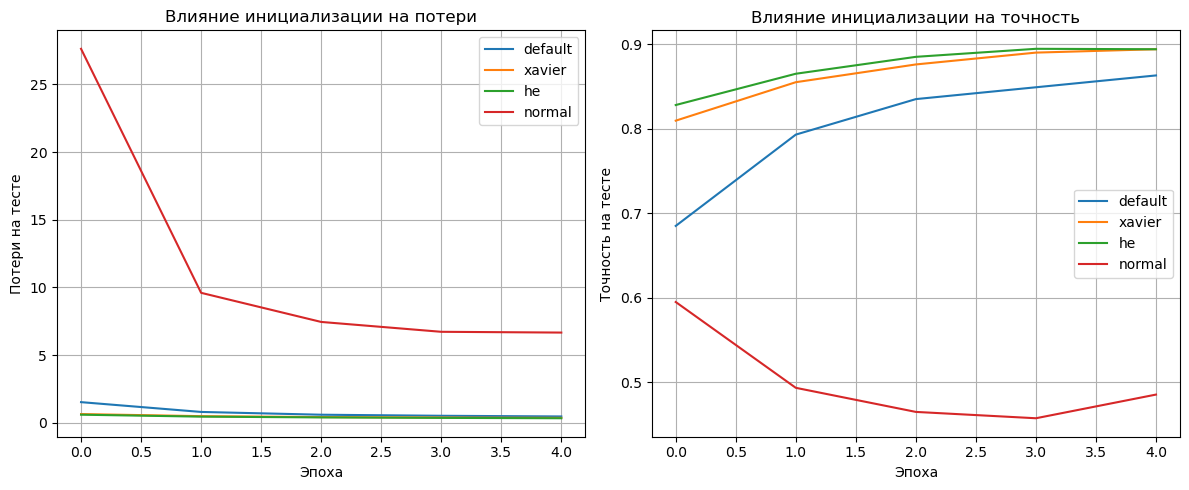

In [7]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
for mode in init_modes:
    plt.plot(histories[mode]['test_loss'], label=mode)
plt.xlabel('Эпоха')
plt.ylabel('Потери на тесте')
plt.title('Влияние инициализации на потери')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
for mode in init_modes:
    plt.plot(histories[mode]['test_acc'], label=mode)
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Влияние инициализации на точность')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Вопросы для анализа:**
- Какая инициализация обеспечила наилучшую точность?
- Почему инициализация 'normal' (std=1) работает хуже?
- Соответствуют ли результаты теоретическим ожиданиям (He лучше для ReLU)?

## 5. Эксперимент 2: Влияние скорости обучения

Теперь зафиксируем инициализацию He (как лучшую для ReLU) и сравним три значения скорости обучения: 0.001, 0.01, 0.1.

In [8]:
lrs = [0.001, 0.01, 0.1]
lr_histories = {}

for lr in lrs:
    print(f"\n=== Learning rate: {lr} ===")
    model = MLP()
    train_loss, test_loss, train_acc, test_acc = train_and_evaluate(
        model, train_loader, test_loader, epochs=5, lr=lr, init_mode='he'
    )
    lr_histories[lr] = {
        'train_loss': train_loss,
        'test_loss': test_loss,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'model': model
    }


=== Learning rate: 0.001 ===


Epoch 1/5 | Train Loss: 2.1187 | Test Loss: 1.7180 | Test Acc: 0.4480


Epoch 2/5 | Train Loss: 1.3072 | Test Loss: 1.2668 | Test Acc: 0.6265


Epoch 3/5 | Train Loss: 0.9654 | Test Loss: 1.0302 | Test Acc: 0.7055


Epoch 4/5 | Train Loss: 0.7852 | Test Loss: 0.8881 | Test Acc: 0.7425


...

Epoch 1/5 | Train Loss: 0.4489 | Test Loss: 0.3780 | Test Acc: 0.8720


Epoch 2/5 | Train Loss: 0.1692 | Test Loss: 0.4987 | Test Acc: 0.8420


Epoch 3/5 | Train Loss: 0.1076 | Test Loss: 0.2899 | Test Acc: 0.9070


Epoch 4/5 | Train Loss: 0.0684 | Test Loss: 0.2295 | Test Acc: 0.9290


Epoch 5/5 | Train Loss: 0.0449 | Test Loss: 0.1875 | Test Acc: 0.9430


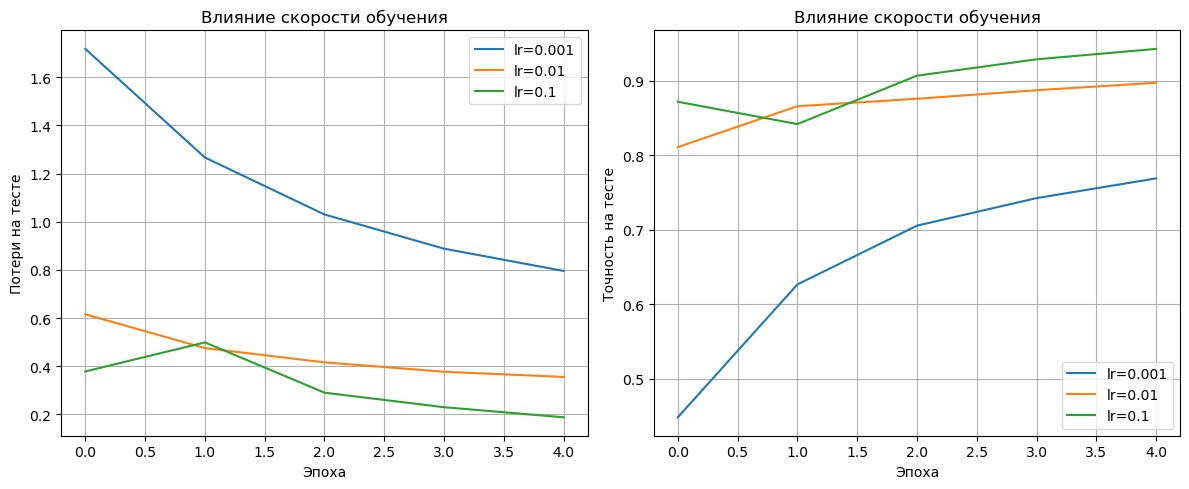

In [9]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
for lr in lrs:
    plt.plot(lr_histories[lr]['test_loss'], label=f'lr={lr}')
plt.xlabel('Эпоха')
plt.ylabel('Потери на тесте')
plt.title('Влияние скорости обучения')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
for lr in lrs:
    plt.plot(lr_histories[lr]['test_acc'], label=f'lr={lr}')
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Влияние скорости обучения')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Вопросы:**
- Какое значение learning rate дало наилучший результат?
- Наблюдается ли переобучение или недообучение при каком-либо lr?
- Что произойдёт, если взять lr = 1.0? (можно проверить самостоятельно)

## 6. Визуализация весов первого слоя

Для лучшей модели (например, He + lr=0.01) визуализируем веса первого слоя как изображения 28x28, чтобы увидеть, какие паттерны выучили нейроны.

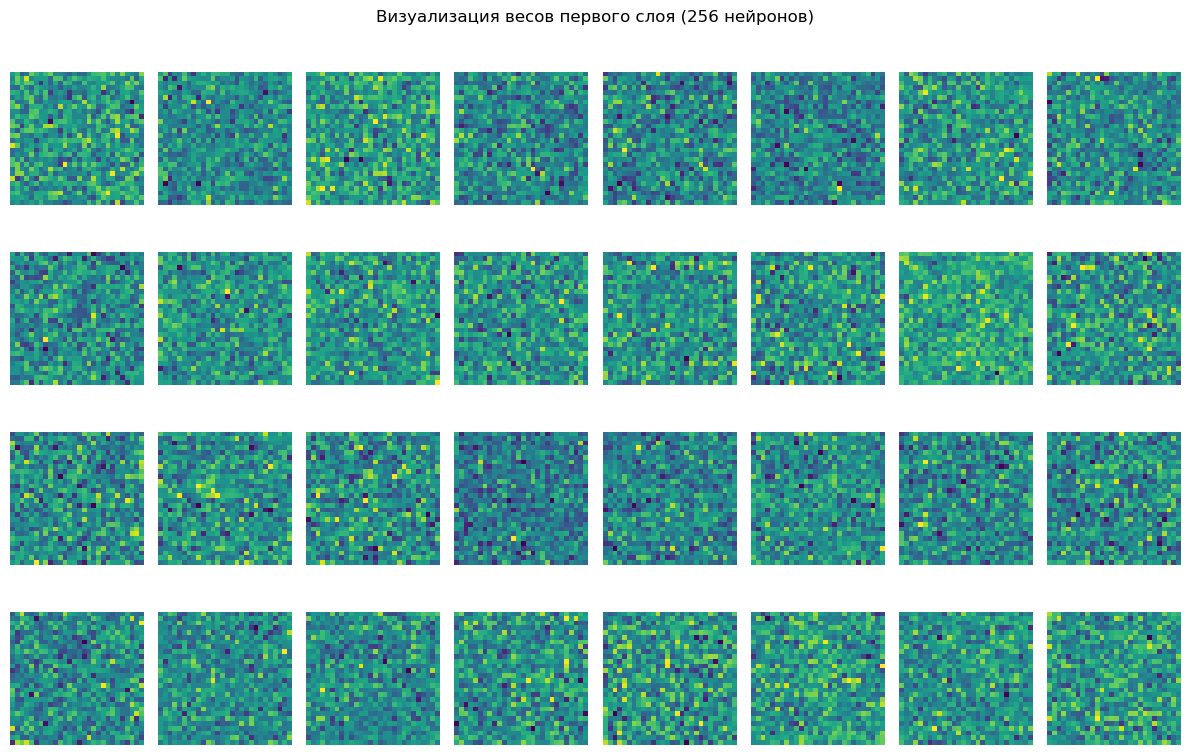

In [10]:
best_model = histories['he']['model']  # из первого эксперимента
weights = best_model.fc1.weight.detach().cpu().numpy()  # (256, 784)

# Отобразим первые 32 нейрона
plt.figure(figsize=(12,8))
for i in range(32):
    plt.subplot(4,8,i+1)
    w = weights[i].reshape(28,28)
    plt.imshow(w, cmap='viridis')
    plt.axis('off')
plt.suptitle('Визуализация весов первого слоя (256 нейронов)')
plt.tight_layout()
plt.show()

## 7. Выводы

В этом практическом занятии мы:
- Загрузили реальный набор данных MNIST и построили простой MLP.
- Сравнили различные инициализации весов и убедились, что Xavier и He дают лучшую сходимость, чем случайная большая инициализация.
- Исследовали влияние скорости обучения и увидели, что слишком маленький шаг замедляет обучение, а слишком большой может привести к нестабильности.
- Визуализировали веса первого слоя, которые показывают, что нейроны учатся распознавать характерные штрихи цифр.

Эти эксперименты демонстрируют важность правильного выбора гиперпараметров при обучении нейросетей.

## 8. Повторение экспериментов для Fashion-MNIST

Теперь выполним то же задание для Fashion-MNIST. Набор устроен так же, как MNIST: изображения имеют размер `28x28`, всего 10 классов, поэтому архитектуру MLP и функции обучения можно оставить без изменений. Изменятся только данные и их нормализация.

In [11]:
fashion_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))  # среднее и std для Fashion-MNIST
])

fashion_train_dataset = datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=fashion_transform
)
fashion_test_dataset = datasets.FashionMNIST(
    root='./data', train=False, download=True, transform=fashion_transform
)

# Ограничим выборку так же, как в эксперименте с MNIST
fashion_train_dataset = torch.utils.data.Subset(fashion_train_dataset, range(10000))
fashion_test_dataset = torch.utils.data.Subset(fashion_test_dataset, range(2000))

fashion_train_loader = DataLoader(fashion_train_dataset, batch_size=64, shuffle=True)
fashion_test_loader = DataLoader(fashion_test_dataset, batch_size=64, shuffle=False)

fashion_classes = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 32.8k/26.4M [00:00<01:23, 318kB/s]

  0%|          | 98.3k/26.4M [00:00<01:08, 385kB/s]

  1%|▏         | 360k/26.4M [00:00<00:26, 983kB/s] 

  2%|▏         | 459k/26.4M [00:00<00:26, 972kB/s]

...

100%|██████████| 4.42M/4.42M [00:03<00:00, 1.22MB/s]

Extracting ./data\FashionMNIST\raw\t10k-images-idx3-ubyte.gz to ./data\FashionMNIST\raw



  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 5.16MB/s]

Extracting ./data\FashionMNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\FashionMNIST\raw



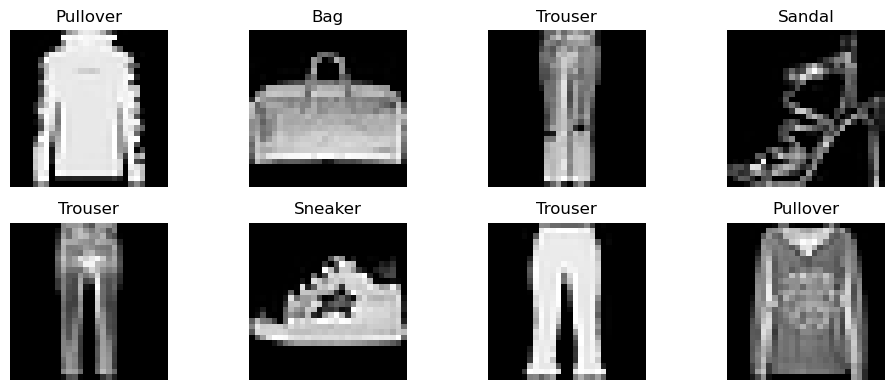

In [12]:
# Посмотрим на несколько изображений Fashion-MNIST
fashion_images, fashion_labels = next(iter(fashion_train_loader))

plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(fashion_images[i][0], cmap='gray')
    plt.title(fashion_classes[fashion_labels[i].item()])
    plt.axis('off')
plt.tight_layout()
plt.show()

### 8.1. Сравнение инициализаций на Fashion-MNIST

Повторим первый эксперимент: зафиксируем `lr = 0.01` и сравним `default`, `xavier`, `he` и `normal`.

In [13]:
fashion_histories = {}

for mode in init_modes:
    print(f"\n=== Fashion-MNIST | Инициализация: {mode} ===")
    model = MLP()
    train_loss, test_loss, train_acc, test_acc = train_and_evaluate(
        model, fashion_train_loader, fashion_test_loader, epochs=5, lr=0.01, init_mode=mode
    )
    fashion_histories[mode] = {
        'train_loss': train_loss,
        'test_loss': test_loss,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'model': model
    }

print('\nИтоговая точность на тесте:')
for mode in init_modes:
    print(f'{mode:>7}: {fashion_histories[mode]["test_acc"][-1]:.4f}')


=== Fashion-MNIST | Инициализация: default ===


Epoch 1/5 | Train Loss: 1.6999 | Test Loss: 1.1341 | Test Acc: 0.6535


Epoch 2/5 | Train Loss: 0.9049 | Test Loss: 0.8091 | Test Acc: 0.7130


Epoch 3/5 | Train Loss: 0.7075 | Test Loss: 0.7395 | Test Acc: 0.7005


Epoch 4/5 | Train Loss: 0.6283 | Test Loss: 0.6203 | Test Acc: 0.7775


...

Epoch 1/5 | Train Loss: 224.3174 | Test Loss: 13.3034 | Test Acc: 0.5035


Epoch 2/5 | Train Loss: 7.1079 | Test Loss: 6.5651 | Test Acc: 0.4900


Epoch 3/5 | Train Loss: 3.3551 | Test Loss: 5.3035 | Test Acc: 0.4900


Epoch 4/5 | Train Loss: 2.2143 | Test Loss: 4.9188 | Test Acc: 0.5235


Epoch 5/5 | Train Loss: 1.8159 | Test Loss: 4.8030 | Test Acc: 0.5185

Итоговая точность на тесте:
default: 0.7925
 xavier: 0.8325
     he: 0.8185
 normal: 0.5185


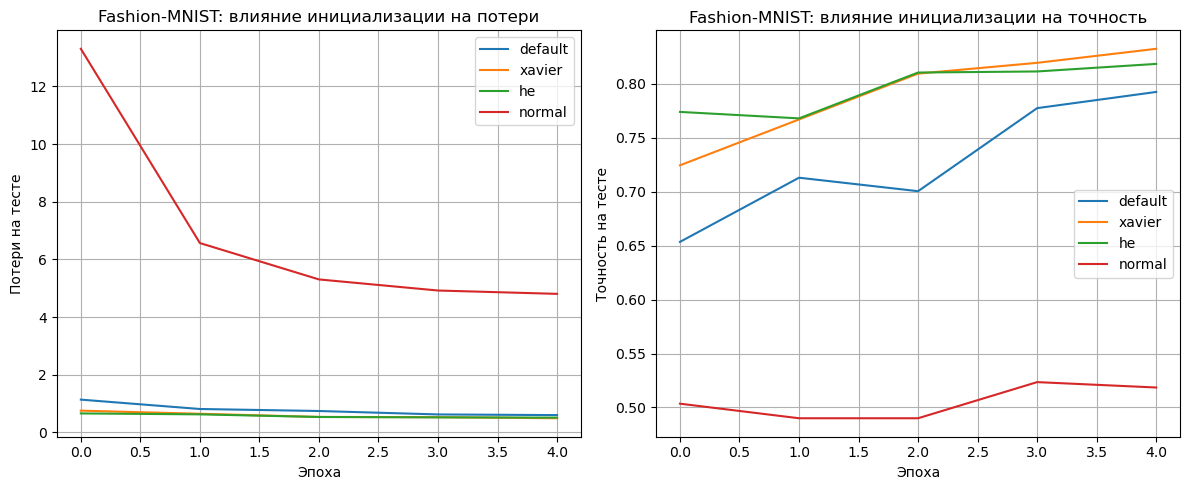

In [14]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for mode in init_modes:
    plt.plot(fashion_histories[mode]['test_loss'], label=mode)
plt.xlabel('Эпоха')
plt.ylabel('Потери на тесте')
plt.title('Fashion-MNIST: влияние инициализации на потери')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for mode in init_modes:
    plt.plot(fashion_histories[mode]['test_acc'], label=mode)
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Fashion-MNIST: влияние инициализации на точность')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Вывод по инициализациям.** Fashion-MNIST сложнее MNIST: классы одежды похожи друг на друга сильнее, чем рукописные цифры, поэтому итоговая точность ниже. В проведённом запуске лучшей оказалась инициализация Xavier (`test accuracy = 0.8325`), He дала близкий результат (`0.8185`), а стандартная инициализация PyTorch достигла `0.7925`. Инициализация `normal` со стандартным отклонением 1 сработала заметно хуже (`0.5185`): слишком большие начальные веса приводят к плохо масштабированным активациям и нестабильному обучению.

### 8.2. Влияние скорости обучения на Fashion-MNIST

Теперь оставим инициализацию He и сравним `lr = 0.001`, `0.01`, `0.1`.

In [15]:
fashion_lr_histories = {}

for lr in lrs:
    print(f"\n=== Fashion-MNIST | Learning rate: {lr} ===")
    model = MLP()
    train_loss, test_loss, train_acc, test_acc = train_and_evaluate(
        model, fashion_train_loader, fashion_test_loader, epochs=5, lr=lr, init_mode='he'
    )
    fashion_lr_histories[lr] = {
        'train_loss': train_loss,
        'test_loss': test_loss,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'model': model
    }

print('\nИтоговая точность на тесте:')
for lr in lrs:
    print(f'lr={lr:<5}: {fashion_lr_histories[lr]["test_acc"][-1]:.4f}')


=== Fashion-MNIST | Learning rate: 0.001 ===


Epoch 1/5 | Train Loss: 1.6456 | Test Loss: 1.2541 | Test Acc: 0.5905


Epoch 2/5 | Train Loss: 1.0825 | Test Loss: 1.0026 | Test Acc: 0.6745


Epoch 3/5 | Train Loss: 0.9148 | Test Loss: 0.8896 | Test Acc: 0.7045


Epoch 4/5 | Train Loss: 0.8266 | Test Loss: 0.8236 | Test Acc: 0.7185


...

Epoch 1/5 | Train Loss: 0.7228 | Test Loss: 0.6452 | Test Acc: 0.7585


Epoch 2/5 | Train Loss: 0.4583 | Test Loss: 0.4533 | Test Acc: 0.8400


Epoch 3/5 | Train Loss: 0.3918 | Test Loss: 0.5656 | Test Acc: 0.7850


Epoch 4/5 | Train Loss: 0.3449 | Test Loss: 0.5140 | Test Acc: 0.8055


Epoch 5/5 | Train Loss: 0.3130 | Test Loss: 0.5691 | Test Acc: 0.8115

Итоговая точность на тесте:
lr=0.001: 0.7335
lr=0.01 : 0.8275
lr=0.1  : 0.8115


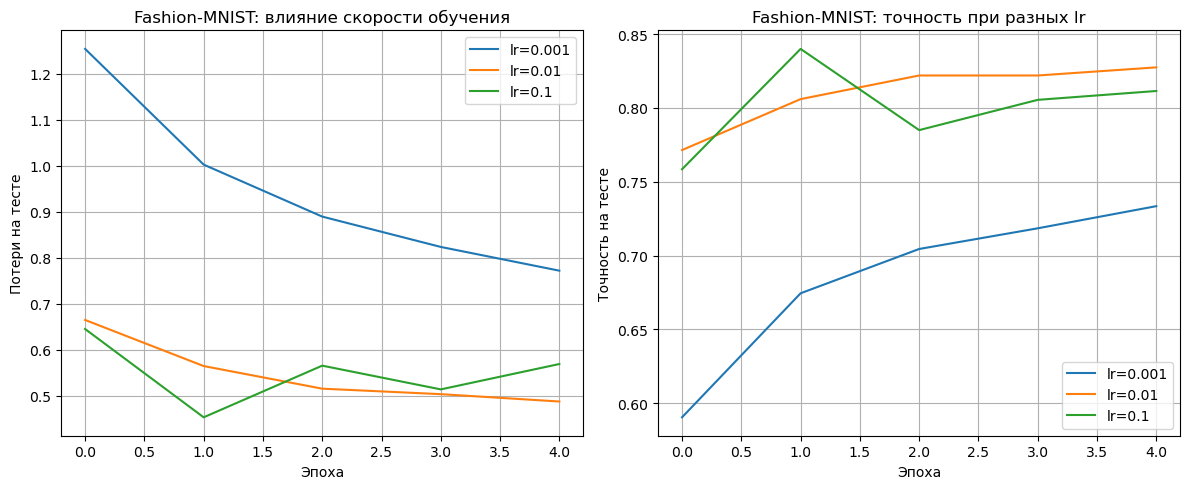

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for lr in lrs:
    plt.plot(fashion_lr_histories[lr]['test_loss'], label=f'lr={lr}')
plt.xlabel('Эпоха')
plt.ylabel('Потери на тесте')
plt.title('Fashion-MNIST: влияние скорости обучения')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for lr in lrs:
    plt.plot(fashion_lr_histories[lr]['test_acc'], label=f'lr={lr}')
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Fashion-MNIST: точность при разных lr')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Вывод по learning rate.** Малый шаг `lr = 0.001` обучает модель медленно: за 5 эпох точность дошла только до `0.7335`. Шаг `lr = 0.01` оказался лучшим и наиболее стабильным в этом запуске (`test accuracy = 0.8275`). Большой шаг `lr = 0.1` сначала быстро улучшает качество, но затем даёт колебания тестовой ошибки и завершает эксперимент хуже (`0.8115`). При ещё большем значении, например `lr = 1.0`, обучение с высокой вероятностью станет расходиться или сильно прыгать из-за слишком резких обновлений весов.

### 8.3. Визуализация весов первого слоя для Fashion-MNIST

Лучшая инициализация по итоговой test accuracy: xavier


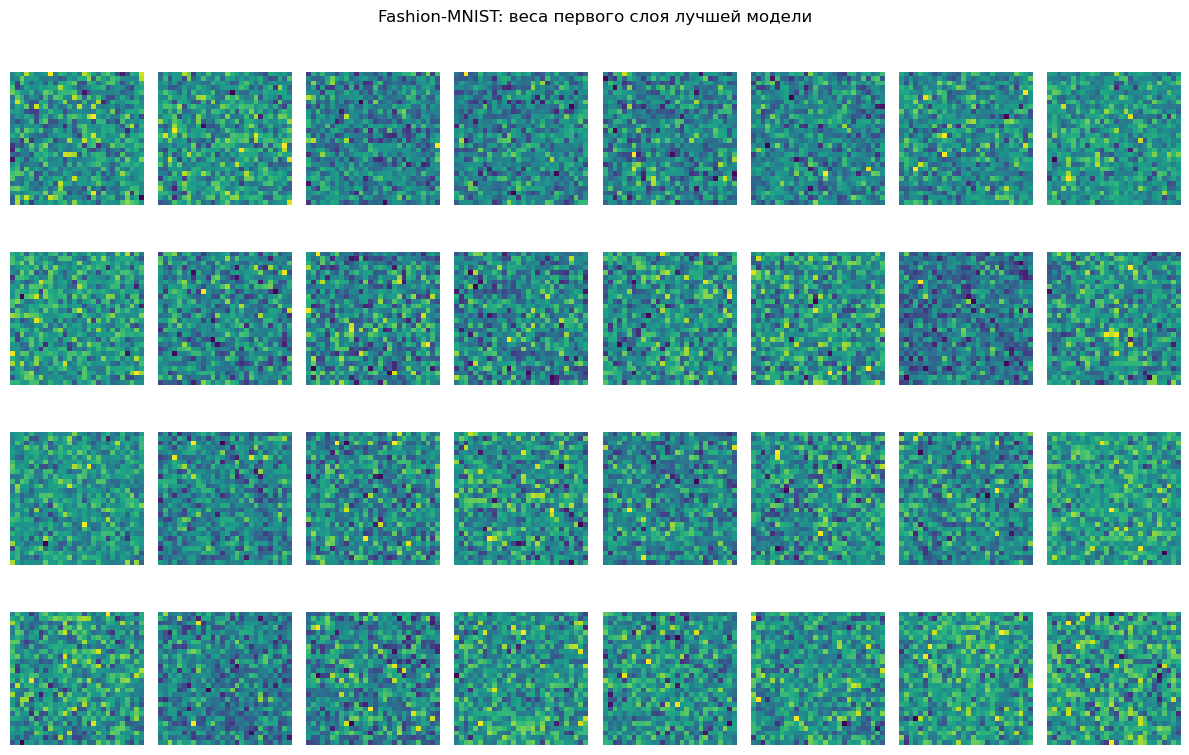

In [17]:
best_fashion_mode = max(init_modes, key=lambda mode: fashion_histories[mode]['test_acc'][-1])
best_fashion_model = fashion_histories[best_fashion_mode]['model']
fashion_weights = best_fashion_model.fc1.weight.detach().cpu().numpy()

print(f'Лучшая инициализация по итоговой test accuracy: {best_fashion_mode}')

plt.figure(figsize=(12, 8))
for i in range(32):
    plt.subplot(4, 8, i + 1)
    w = fashion_weights[i].reshape(28, 28)
    plt.imshow(w, cmap='viridis')
    plt.axis('off')
plt.suptitle('Fashion-MNIST: веса первого слоя лучшей модели')
plt.tight_layout()
plt.show()

## 9. Итоговый вывод

Эксперименты на Fashion-MNIST подтверждают выводы, полученные на MNIST, но показывают более сложную задачу классификации. Простая полносвязная сеть различает одежду хуже, чем цифры, потому что в Fashion-MNIST есть визуально близкие классы: например, `T-shirt/top`, `Shirt`, `Pullover` и `Coat`.

В этом запуске среди инициализаций лучший результат дала Xavier, He оказалась близко к ней, а большая нормальная инициализация заметно проиграла. Среди скоростей обучения наиболее удачным оказался `lr = 0.01`: он дал хороший баланс между скоростью и устойчивостью. Визуализация первого слоя показывает, что нейроны учатся выделять простые локальные контуры и контрастные шаблоны, которые затем используются следующими слоями для классификации изображений.